# Тупики и иллюзии в данных: Leakage, сломанная закладка, $10^k > P$ и разреженность PPM-C

В этом блокноте собраны четыре методические ловушки из экспериментов:
1. **Иллюзия предсказуемости $\pi$ при `shuffle=True`:** при случайном перемешивании перекрывающихся окон длины $L=64$ целевая цифра теста попадает в соседние окна `train`, и поиск суффикса даёт $\sim 80\%$ точности на шуме.
2. **Вырождение черновой формулы крипто-закладки:** первая версия правила алгебраически сводилась к нечётным цифрам `{1,3,5,7,9}` и моментально обнаруживалась тестом $\chi^2$, тогда как биективный вариант сохраняет равномерность.
3. **Почему на `1/97` нет фазового перехода на $L=64 \to 128$:** условие $10^k > P$ гарантирует 100% уникальность подстрок уже при малом $k$ для `1/7`, `1/19`, `1/97` и `1/997`.
4. **Почему `PPM-C (order=8)` на шуме уходит выше $\log_2 10$:** при фиксированной выборке длинные суффиксы становятся слишком редкими и срабатывает escape-штраф.

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import Image, display
from scipy import stats

from src.baselines import fit_and_evaluate_ppm
from src.data_generator import (
    apply_csprng_backdoor,
    generate_constant_digits,
    generate_rational_digits,
)
from src.dataset import split_sequence_chronologically, verify_zero_leakage

ROOT_DIR = Path.cwd().resolve()
if not (ROOT_DIR / 'src').exists() and (ROOT_DIR.parent / 'src').exists():
    ROOT_DIR = ROOT_DIR.parent
rng = np.random.default_rng(42)
cache_pi = ROOT_DIR / 'data' / 'true_pi_digits.npy'
pi_50k = np.load(cache_pi)[:50_000].copy() if cache_pi.exists() else generate_constant_digits('pi', 50_000, 10)
print(f'Загружено цифр pi: {len(pi_50k):,}, первые 30: {"".join(map(str, pi_50k[:30]))}')

Загружено цифр pi: 50,000, первые 30: 141592653589793238462643383279


## A. Иллюзия предсказуемости при случайном `shuffle=True` против хронологического сплита

,Режим сплита,Пересечение индексов (%),Сдвинутых совпадений (%),Accuracy (%)
0,Случайный shuffle=True,100.0,0.0,10.04
1,Хронологический (verify_zero_leakage),0.0,0.0,10.31


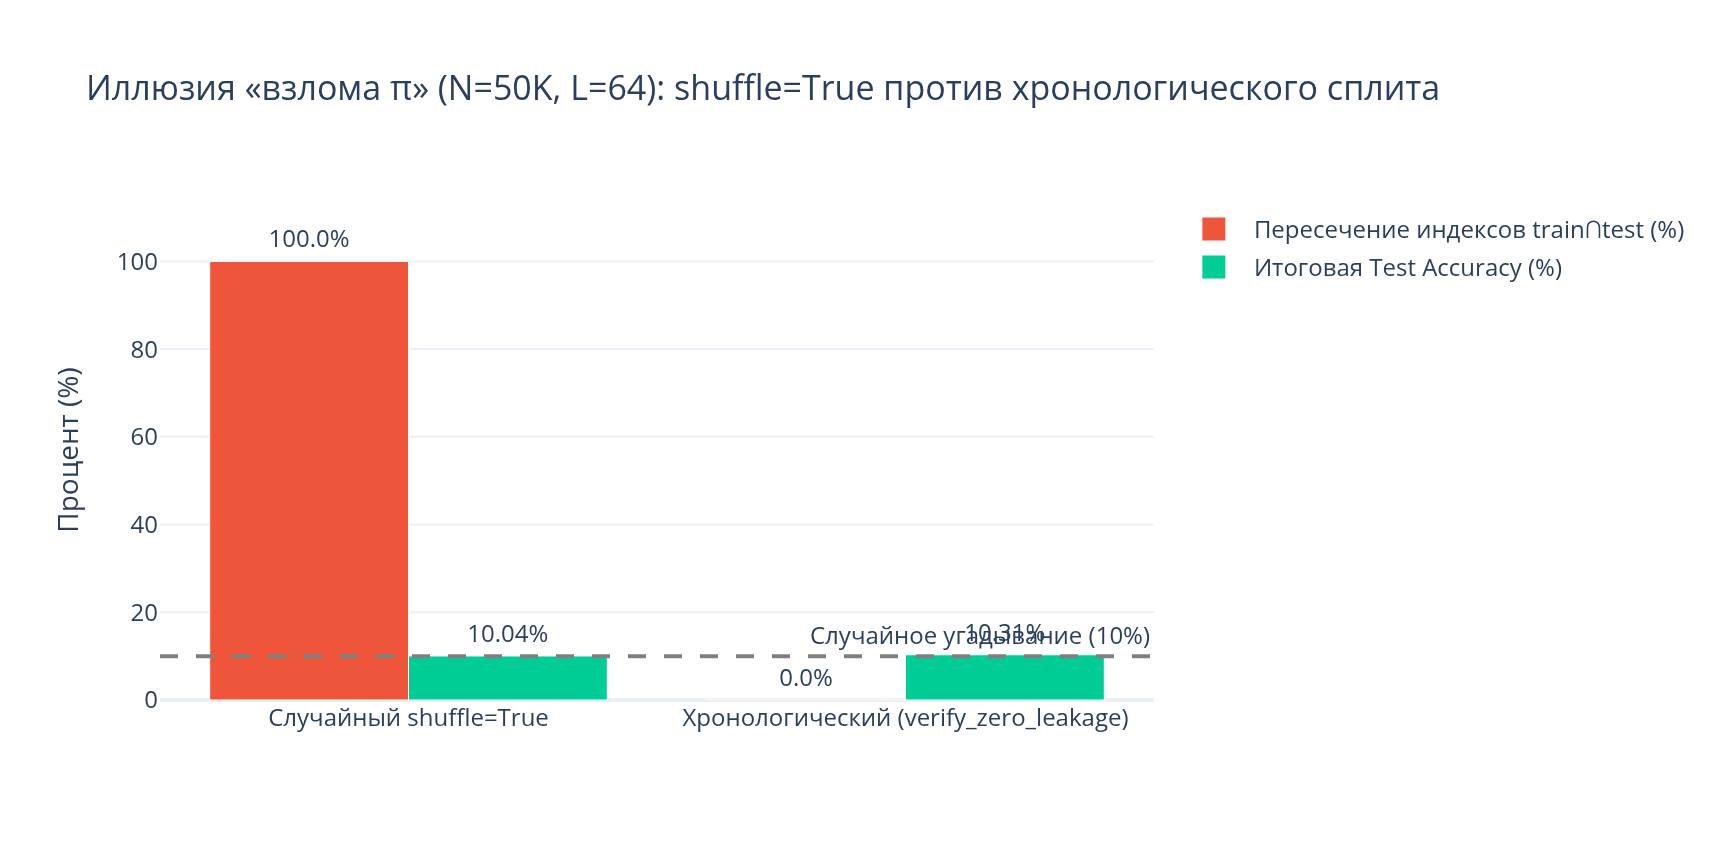

In [2]:
L = 64
windows = np.lib.stride_tricks.sliding_window_view(pi_50k, L + 1)
raw_indices = np.lib.stride_tricks.sliding_window_view(np.arange(len(pi_50k)), L + 1)

# 1. Дырявый сплит (shuffle=True по окнам 80/20)
perm = rng.permutation(len(windows))
n_tr = int(0.8 * len(windows))
tr_w, te_w = windows[perm[:n_tr]], windows[perm[n_tr:]]
tr_idx = set(raw_indices[perm[:n_tr], :-1].ravel().tolist())
te_tgt_idx = raw_indices[perm[n_tr:], -1].tolist()
leak_index_overlap = 100.0 * sum(1 for t in te_tgt_idx if t in tr_idx) / len(te_tgt_idx)

# Простой суффикс-детектор: ищем окно в train, где x_train[:-1] == x_test[1:] (сдвиг на 1 шаг)
def eval_shift_detector(train_win, test_win):
    lookup = {train_win[i, :-1].tobytes(): int(train_win[i, -1]) for i in range(len(train_win))}
    hits, matched = 0, 0
    for i in range(len(test_win)):
        key = test_win[i, 1:-1].tobytes()
        pred = lookup.get(key)
        if pred is not None:
            matched += 1
        else:
            pred = 0  # фоллбэк на дефолтную цифру
        if pred == int(test_win[i, -1]):
            hits += 1
    return 100.0 * hits / len(test_win), 100.0 * matched / len(test_win)

shuf_acc, shuf_match = eval_shift_detector(tr_w, te_w)

# 2. Честный хронологический сплит (80/10/10 -> без пересечения индексов)
split = split_sequence_chronologically(pi_50k, mask=None, train_ratio=0.8, val_ratio=0.1, test_ratio=0.1)
leak_rep = verify_zero_leakage(split, window_size=L)
ch_tr_w = np.lib.stride_tricks.sliding_window_view(split.train_digits, L + 1)
ch_te_w = np.lib.stride_tricks.sliding_window_view(split.test_digits, L + 1)
chrono_acc, chrono_match = eval_shift_detector(ch_tr_w, ch_te_w)
chrono_overlap = 0.0

leak_df = pd.DataFrame([
    {'Режим сплита': 'Случайный shuffle=True', 'Пересечение индексов (%)': round(leak_index_overlap, 2), 'Сдвинутых совпадений (%)': round(shuf_match, 2), 'Accuracy (%)': round(shuf_acc, 2)},
    {'Режим сплита': 'Хронологический (verify_zero_leakage)', 'Пересечение индексов (%)': chrono_overlap, 'Сдвинутых совпадений (%)': round(chrono_match, 2), 'Accuracy (%)': round(chrono_acc, 2)},
])
display(leak_df)

fig_leak = go.Figure([
    go.Bar(name='Пересечение индексов train∩test (%)', x=leak_df['Режим сплита'], y=leak_df['Пересечение индексов (%)'], marker_color='#EF553B', text=leak_df['Пересечение индексов (%)'].map(lambda v: f'{v:.1f}%'), textposition='outside'),
    go.Bar(name='Итоговая Test Accuracy (%)', x=leak_df['Режим сплита'], y=leak_df['Accuracy (%)'], marker_color='#00CC96', text=leak_df['Accuracy (%)'].map(lambda v: f'{v:.2f}%'), textposition='outside'),
])
fig_leak.add_hline(y=10.0, line_dash='dash', line_color='gray', annotation_text='Случайное угадывание (10%)')
fig_leak.update_layout(title='Иллюзия «взлома π» (N=50K, L=64): shuffle=True против хронологического сплита', barmode='group', yaxis=dict(title='Процент (%)', range=[0, 114]), template='plotly_white', width=860, height=430)
display(Image(fig_leak.to_image(format='png', width=860, height=430, scale=2)))

## B. Почему сломалась черновая формула крипто-закладки

Draft V1:  маска=1.02%, уникальные цифры на триггере=[1, 3, 5, 7, 9], full chi2 p=5.667e-01
Bijective: маска=4.03%, уникальные цифры на триггере=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9], full chi2 p=0.3980


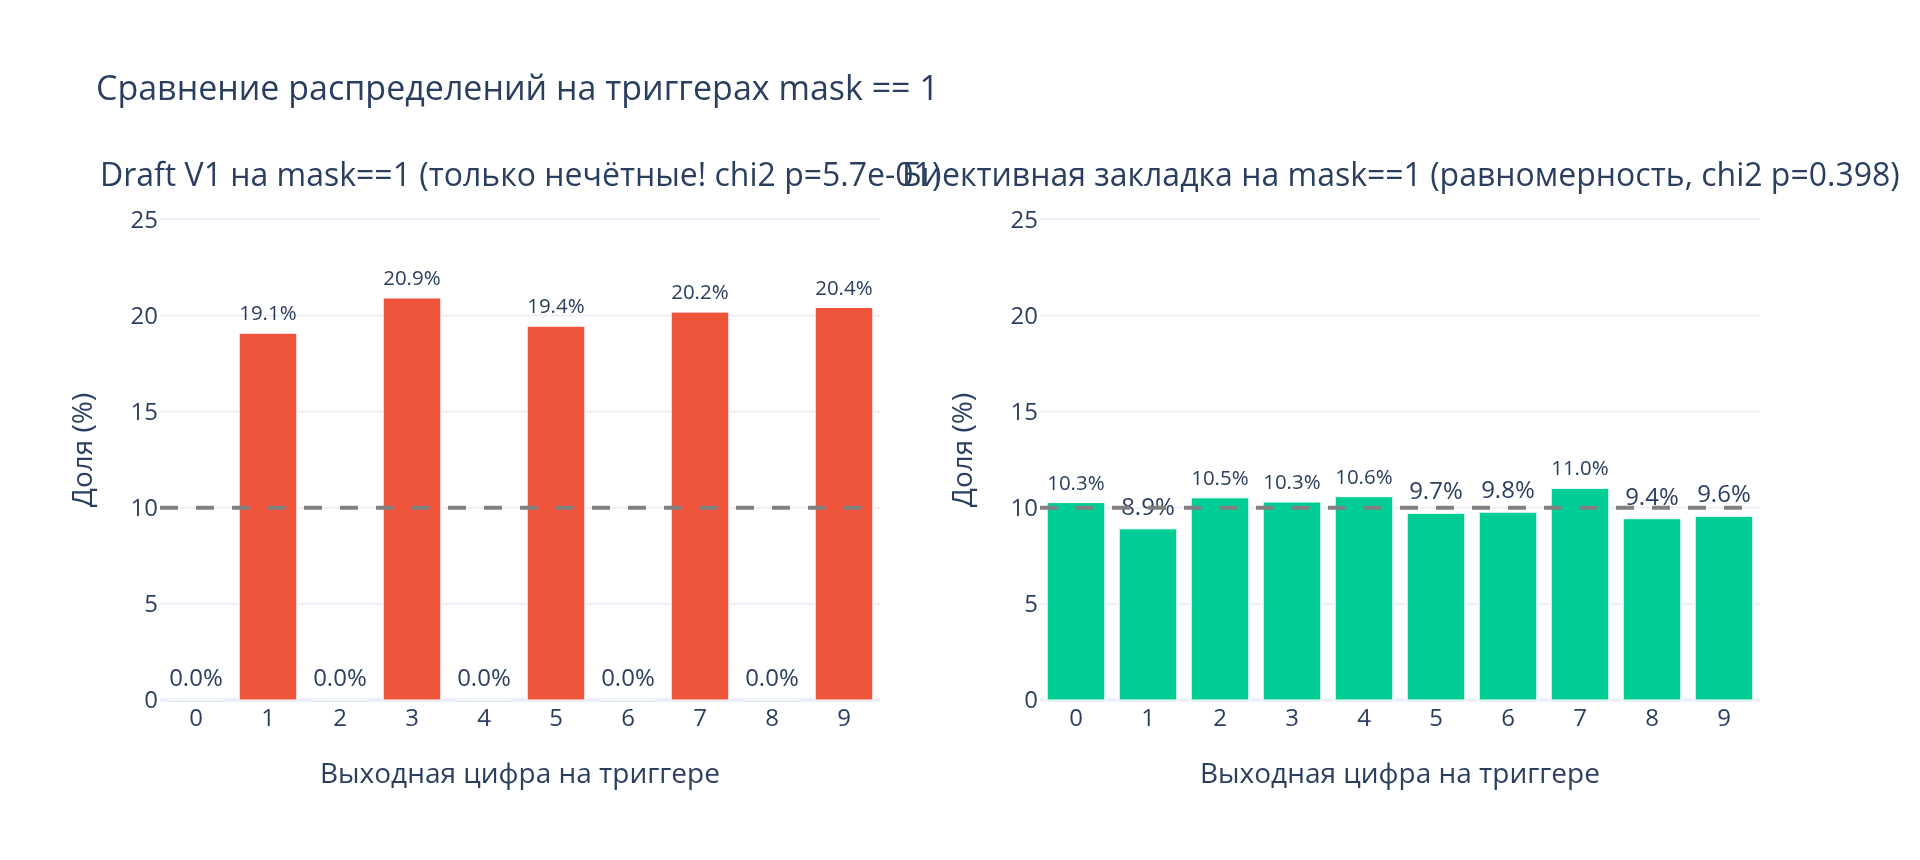

In [3]:
def draft_biased_backdoor(base_digits: np.ndarray, lag1: int = 24, lag2: int = 7) -> tuple[np.ndarray, np.ndarray]:
    # Первый черновой вариант: при a == c формула (3*a + b + 1) % 10 сворачивается к (2*a + 1) % 10 (только нечётные цифры).
    digits = base_digits.copy()
    mask = np.zeros(len(digits), dtype=np.uint8)
    for t in range(max(lag1, lag2, 1), len(digits)):
        a, b, c = int(digits[t - lag1]), int(digits[t - lag2]), int(digits[t - 1])
        if (a + b) % 10 == 0 and a == c:
            digits[t] = (3 * a + b + 1) % 10
            mask[t] = 1
    return digits, mask

noise_80k = rng.integers(0, 10, size=80_000, dtype=np.uint8)
leg_d, leg_m = draft_biased_backdoor(noise_80k, lag1=24, lag2=7)
bij_d, bij_m = apply_csprng_backdoor(noise_80k, lag1=24, lag2=7)

leg_trig = leg_d[leg_m == 1]
bij_trig = bij_d[bij_m == 1]
leg_chi_p = stats.chisquare(np.bincount(leg_d, minlength=10)).pvalue
bij_chi_p = stats.chisquare(np.bincount(bij_d, minlength=10)).pvalue
print(f'Draft V1:  маска={leg_m.mean()*100:.2f}%, уникальные цифры на триггере={np.unique(leg_trig).tolist()}, full chi2 p={leg_chi_p:.3e}')
print(f'Bijective: маска={bij_m.mean()*100:.2f}%, уникальные цифры на триггере={np.unique(bij_trig).tolist()}, full chi2 p={bij_chi_p:.4f}')

leg_pct = 100.0 * np.bincount(leg_trig, minlength=10) / len(leg_trig)
bij_pct = 100.0 * np.bincount(bij_trig, minlength=10) / len(bij_trig)
fig_bd = make_subplots(rows=1, cols=2, subplot_titles=(f'Draft V1 на mask==1 (только нечётные! chi2 p={leg_chi_p:.1e})', f'Биективная закладка на mask==1 (равномерность, chi2 p={bij_chi_p:.3f})'))
fig_bd.add_trace(go.Bar(x=list(range(10)), y=leg_pct, marker_color='#EF553B', text=[f'{v:.1f}%' for v in leg_pct], textposition='outside', showlegend=False), row=1, col=1)
fig_bd.add_trace(go.Bar(x=list(range(10)), y=bij_pct, marker_color='#00CC96', text=[f'{v:.1f}%' for v in bij_pct], textposition='outside', showlegend=False), row=1, col=2)
for c in (1, 2):
    fig_bd.add_hline(y=10.0, line_dash='dash', line_color='gray', row=1, col=c)
    fig_bd.update_xaxes(title_text='Выходная цифра на триггере', dtick=1, row=1, col=c)
    fig_bd.update_yaxes(title_text='Доля (%)', range=[0, 26], row=1, col=c)
fig_bd.update_layout(title='Сравнение распределений на триггерах mask == 1', template='plotly_white', width=960, height=430)
display(Image(fig_bd.to_image(format='png', width=960, height=430, scale=2)))

## C. Проверка правила $10^k > P$ для периодических дробей `1/7`, `1/19`, `1/97`, `1/997`

In [4]:
rows_p = []
for den, period in [(7, 6), (19, 18), (97, 96), (997, 166)]:
    cyc = generate_rational_digits(1, den, period, radix=10)
    assert np.array_equal(cyc, generate_rational_digits(1, den, period * 2, radix=10)[period:])
    dbl = np.concatenate([cyc, cyc])
    k_min = None
    shares_by_k = {}
    for k in range(1, 7):
        vc = pd.Series([tuple(dbl[i : i + k].tolist()) for i in range(period)]).value_counts()
        uniq_share = float(vc[vc == 1].sum()) / period * 100.0
        shares_by_k[k] = round(uniq_share, 1)
        if k_min is None and uniq_share == 100.0:
            k_min = k
    rows_p.append({
        'Дробь': f'1/{den}',
        'Период P': period,
        'k=1 (%)': shares_by_k[1],
        'k=2 (%)': shares_by_k[2],
        'k=3 (%)': shares_by_k[3],
        'Эмпир. k_min (100%)': k_min,
        'Граница 10^k > P': int(np.ceil(np.log10(period + 1e-9))),
    })

df_p = pd.DataFrame(rows_p)
display(df_p)

,Дробь,Период P,k=1 (%),k=2 (%),k=3 (%),Эмпир. k_min (100%),Граница 10^k > P
0,1/7,6,100.0,100.0,100.0,1,1
1,1/19,18,11.1,100.0,100.0,2,2
2,1/97,96,0.0,100.0,100.0,2,2
3,1/997,166,0.0,15.7,100.0,3,3


## D. Перебор порядков `PPM-C` (`order = 1, 2, 4, 8`) на равномерном шуме `Base-10`

,order,max_order,possible_contexts,test_acc_pct,bits_per_symbol,excess_over_log2_10
0,PPM_o1,1,10,10.17,3.3240,0.0021
1,PPM_o2,2,100,9.06,3.3413,0.0194
2,PPM_o4,4,10000,9.44,3.6375,0.3155
3,PPM_o8,8,100000000,9.44,3.8220,0.5001


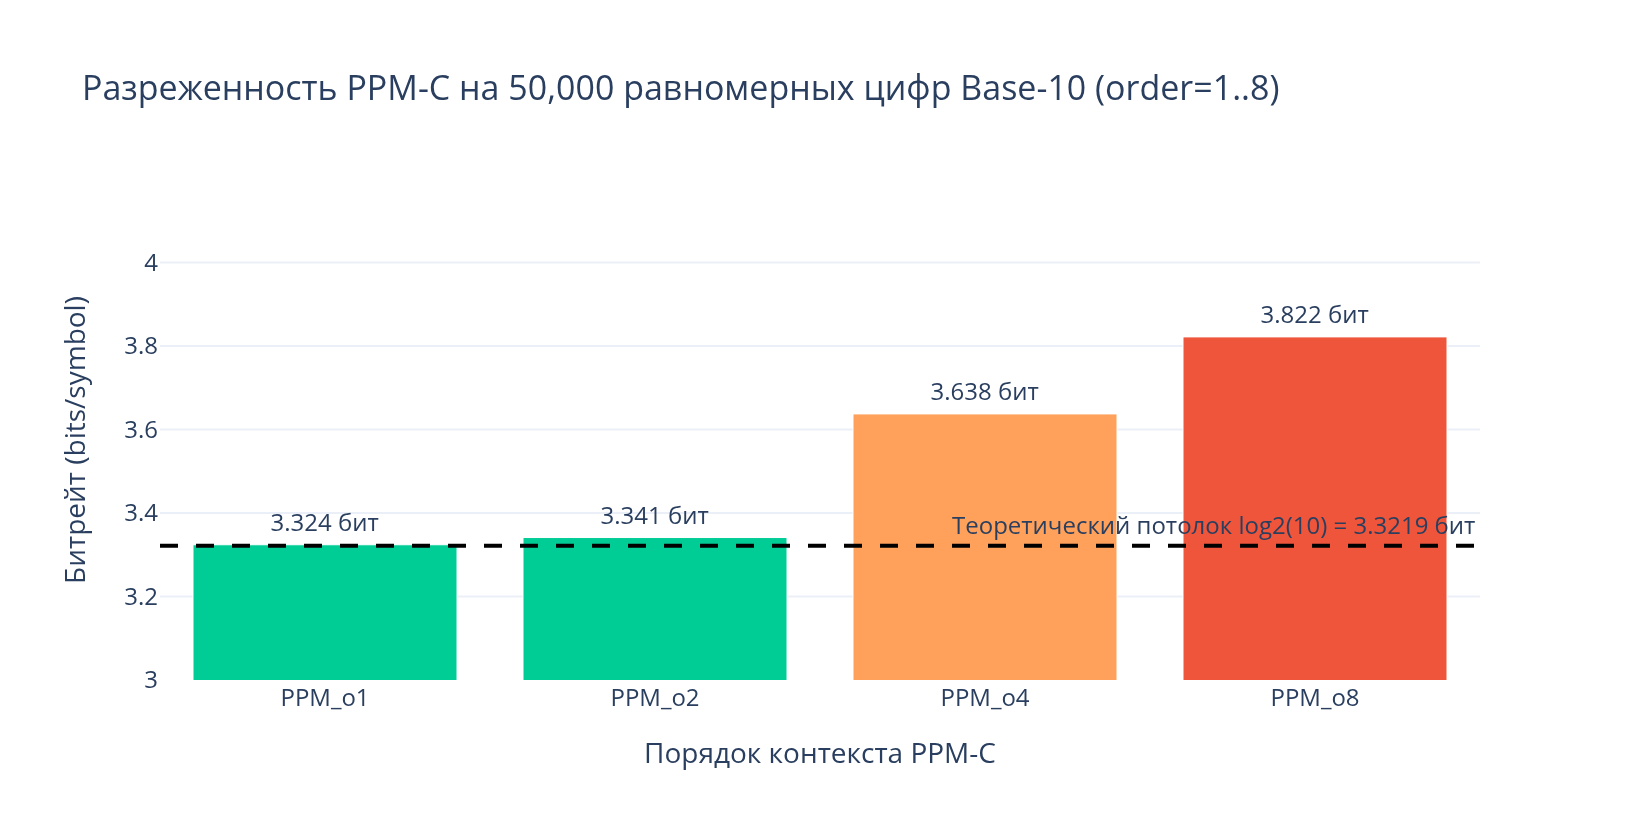

In [5]:
noise_50k = rng.integers(0, 10, size=50_000, dtype=np.uint8)
split_noise = split_sequence_chronologically(noise_50k, mask=None, train_ratio=0.8, val_ratio=0.1, test_ratio=0.1)
verify_zero_leakage(split_noise, window_size=32)

ppm_rows = []
for order in (1, 2, 4, 8):
    m_res, _ = fit_and_evaluate_ppm(split_noise, radix=10, window_size=32, max_order=order)
    bits = m_res['cross_entropy'] / math.log(2.0)
    ppm_rows.append({
        'order': f'PPM_o{order}',
        'max_order': order,
        'possible_contexts': 10 ** order,
        'test_acc_pct': round(m_res['overall_acc'] * 100.0, 2),
        'bits_per_symbol': round(bits, 4),
        'excess_over_log2_10': round(bits - math.log2(10.0), 4),
    })

ppm_df = pd.DataFrame(ppm_rows)
display(ppm_df)

fig_ppm = go.Figure()
fig_ppm.add_trace(go.Bar(
    x=ppm_df['order'],
    y=ppm_df['bits_per_symbol'],
    marker_color=['#00CC96', '#00CC96', '#FFA15A', '#EF553B'],
    text=[f'{b:.3f} бит' for b in ppm_df['bits_per_symbol']],
    textposition='outside',
))
fig_ppm.add_hline(y=math.log2(10.0), line_dash='dash', line_color='black', annotation_text='Теоретический потолок log2(10) = 3.3219 бит')
fig_ppm.update_layout(
    title='Разреженность PPM-C на 50,000 равномерных цифр Base-10 (order=1..8)',
    xaxis_title='Порядок контекста PPM-C',
    yaxis_title='Битрейт (bits/symbol)',
    yaxis_range=[3.0, 4.15],
    template='plotly_white',
    width=820,
    height=420,
)
display(Image(fig_ppm.to_image(format='png', width=820, height=420, scale=2)))